# KRS Dam: Next-Day Storage Prediction and Drought Alert


## 1. Import libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, log_loss, confusion_matrix)

## 2. Load data (all Karnataka reservoirs) and keep KRS

In [11]:
df=pd.read_csv('karnataka_man_reservoir_data.csv')
print('All reservoirs:',df.shape)
df=df[df['Reservoir Name']=='K.R.Sagara Dam']
df=df.rename(columns={'Monitoring Date':'Date','Reservoir Level (ft)':'Level_ft','Live Capacity \n(TMC)':'Live_TMC',
                      'Inflow (Cusecs)':'Inflow','Outflow to River (Cusecs)':'Outflow','Canal Withdrawal (Cusecs)':'Canal'})
df=df[['Date','Level_ft','Live_TMC','Inflow','Outflow','Canal']]
# the time of day differs (12:01, 12:12 ...), so keep only the date part (dd-mm-yyyy)
df['Date']=pd.to_datetime(df['Date'].str[:10],format='%d-%m-%Y')
df=df.sort_values('Date').reset_index(drop=True)
print('KRS:',df.shape,'| from',df['Date'].min().date(),'to',df['Date'].max().date())
df.head()

All reservoirs: (125270, 19)
KRS: (13450, 6) | from 1990-01-01 to 2026-10-29


,Date,Level_ft,Live_TMC,Inflow,Outflow,Canal
0,1990-01-01,2457.30,26.794,901.0,433.0,2583.0
1,1990-01-02,2457.12,26.597,1250.0,430.0,2542.0
2,1990-01-03,2456.97,26.434,2159.0,418.0,2450.0
3,1990-01-04,2456.90,26.359,1418.0,418.0,2450.0
4,1990-01-05,2456.77,26.221,1542.0,418.0,2450.0


Other columns were left out: `Percentage Full` is about 80% empty, and evaporation and the cumulative columns are not needed for this question.

## 3. Inspect and clean

In [12]:
df.info()
display(df.describe().T)
print(df.isnull().sum())
print('Duplicate dates:',df['Date'].duplicated().sum())
print('Calendar days from first to last record:',(df['Date'].max()-df['Date'].min()).days+1,'| rows:',len(df))

<class 'pandas.DataFrame'>
RangeIndex: 13450 entries, 0 to 13449
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      13450 non-null  datetime64[us]
 1   Level_ft  13450 non-null  float64       
 2   Live_TMC  13450 non-null  float64       
 3   Inflow    13443 non-null  float64       
 4   Outflow   13450 non-null  float64       
 5   Canal     13450 non-null  float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 630.6 KB


,count,mean,min,25%,50%,75%,max,std
Date,13450,2008-05-30 16:22:31.137546,1990-01-01 00:00:00,1999-03-17 06:00:00,2008-05-30 12:00:00,2017-08-13 18:00:00,2026-10-29 00:00:00,NaN
Level_ft,13450.0,2449.221754,2406.8,2434.28,2451.62,2464.8,14782.0,107.748198
Live_TMC,13450.0,21.229805,0.0,7.71275,21.018,35.6885,60.943,14.249899
Inflow,13443.0,4822.314811,0.0,368.0,1557.0,5021.0,204200.0,9985.525856
Outflow,13450.0,2698.901692,0.0,517.0,929.0,1546.75,180147.0,8097.071283
Canal,13450.0,1878.895686,0.0,100.0,2491.0,2914.75,4106.0,1359.535494


Date        0
Level_ft    0
Live_TMC    0
Inflow      7
Outflow     0
Canal       0
dtype: int64
Duplicate dates: 0
Calendar days from first to last record: 13451 | rows: 13450


In [13]:
# remove duplicates
df=df.drop_duplicates(subset='Date')

# a few missing inflow values -> median (inflow is very skewed, so the mean would be pulled up by floods)
print("Inflow skewness:", df['Inflow'].skew())
df['Inflow']=df['Inflow'].fillna(df['Inflow'].median())

# outliers with the IQR rule (as in lecture 3)
def detect_outliers(col):
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr=q3-q1
    lb=q1-1.5*iqr
    ub=q3+1.5*iqr
    return df[(df[col]<lb)|(df[col]>ub)]
for col in ['Inflow','Outflow','Canal']:
    print(col,'IQR outliers:',len(detect_outliers(col)))

Inflow skewness: 6.113125266558815
Inflow IQR outliers: 1349
Outflow IQR outliers: 1805
Canal IQR outliers: 0


The IQR outliers in inflow and outflow are monsoon floods (up to about 200,000 cusecs). They are real events, so they are **kept**.

## 4. Create features and targets, remove impossible records
- `Net_Flux_TMC` = (inflow − outflow − canal withdrawal) in TMC per day (1 cusec for a day = 0.0000864 TMC).
- Regression target = next day's `Live_TMC` (the next row). Classification target = 1 if next-day storage is below 12.363 TMC.
- Some records cannot be right and are **removed**: next record not exactly one day later, reservoir level above the full level (typing error), storage above the design capacity, or a storage jump of more than 8 TMC in one day although the net flow is below 1 TMC (floods are kept, because their flow explains the rise).

In [14]:
df['Net_Flux_TMC']=(df['Inflow']-df['Outflow']-df['Canal'])*8.64e-5

# tomorrow's values = the next row (the last day has no tomorrow)
dates=df['Date'].values
live=df['Live_TMC'].values
df=df.iloc[:-1].copy()
df['Next_Date']=dates[1:]
df['Next_Live_TMC']=live[1:]

# records that cannot be right
one_day=(df['Next_Date']-df['Date']).dt.days==1                            # next record must be exactly one day later
level_ok=df['Level_ft']<=2470                                               # above the full reservoir level (2468.8 ft) = typing error
too_big=(df['Live_TMC']>49.452)|(df['Next_Live_TMC']>49.452)                # storage above the design capacity
jump=((df['Next_Live_TMC']-df['Live_TMC']).abs()>8)&(df['Net_Flux_TMC'].abs()<1)   # jumps >8 TMC in a day with almost no net flow
print('Not one day apart:',(~one_day).sum(),'| level typos:',(~level_ok).sum(),'| above capacity:',too_big.sum(),'| jump without flow:',jump.sum())
print(df.loc[~level_ok|too_big|jump,['Date','Level_ft','Live_TMC','Next_Live_TMC']].to_string(index=False))

df=df[one_day & level_ok & ~too_big & ~jump].reset_index(drop=True)
df['Drought_Alert']=(df['Next_Live_TMC']<12.363).astype(int)
print('Rows used:',len(df))
print('Drought-alert days: %.1f%%'%(df['Drought_Alert'].mean()*100))
df[['Date','Live_TMC','Net_Flux_TMC','Next_Live_TMC','Drought_Alert']].head()

Not one day apart: 1 | level typos: 2 | above capacity: 6 | jump without flow: 6
      Date  Level_ft  Live_TMC  Next_Live_TMC
1992-08-28  14782.00    40.487         40.668
1999-02-25   2448.14    17.852         50.524
1999-02-26   2447.76    50.524         17.164
2001-01-20   2456.94    26.402         16.114
2001-01-21   2456.67    16.114         25.815
2011-02-13   2461.23    31.264         60.943
2011-02-14   2460.96    60.943         60.592
2011-02-15   2460.66    60.592         60.252
2011-02-16   2460.37    60.252         29.889
2015-01-18   2499.90    29.705         29.327
Rows used: 13438
Drought-alert days: 34.0%


,Date,Live_TMC,Net_Flux_TMC,Next_Live_TMC,Drought_Alert
0,1990-01-01,26.794,-0.182736,26.597,0
1,1990-01-02,26.597,-0.148781,26.434,0
2,1990-01-03,26.434,-0.061258,26.359,0
3,1990-01-04,26.359,-0.125280,26.221,0
4,1990-01-05,26.221,-0.114566,26.093,0


## 5. Explore the data

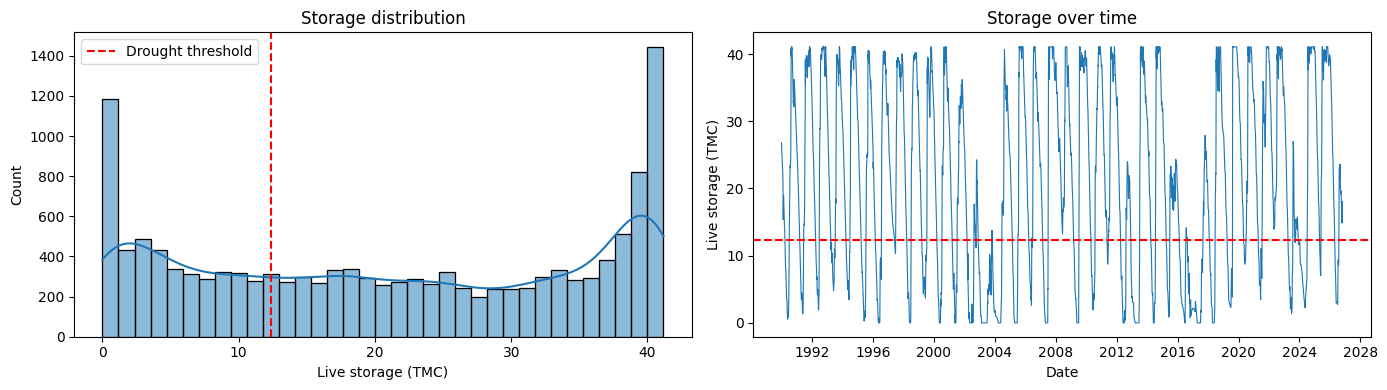

In [15]:
fig,ax=plt.subplots(1,2,figsize=(14,4))
sns.histplot(df['Live_TMC'],bins=35,kde=True,ax=ax[0])
ax[0].axvline(12.363,color='red',linestyle='--',label='Drought threshold')
ax[0].set_title('Storage distribution'); ax[0].set_xlabel('Live storage (TMC)'); ax[0].legend()
ax[1].plot(df['Date'],df['Live_TMC'],linewidth=0.8)
ax[1].axhline(12.363,color='red',linestyle='--')
ax[1].set_title('Storage over time'); ax[1].set_xlabel('Date'); ax[1].set_ylabel('Live storage (TMC)')
plt.tight_layout(); plt.show()

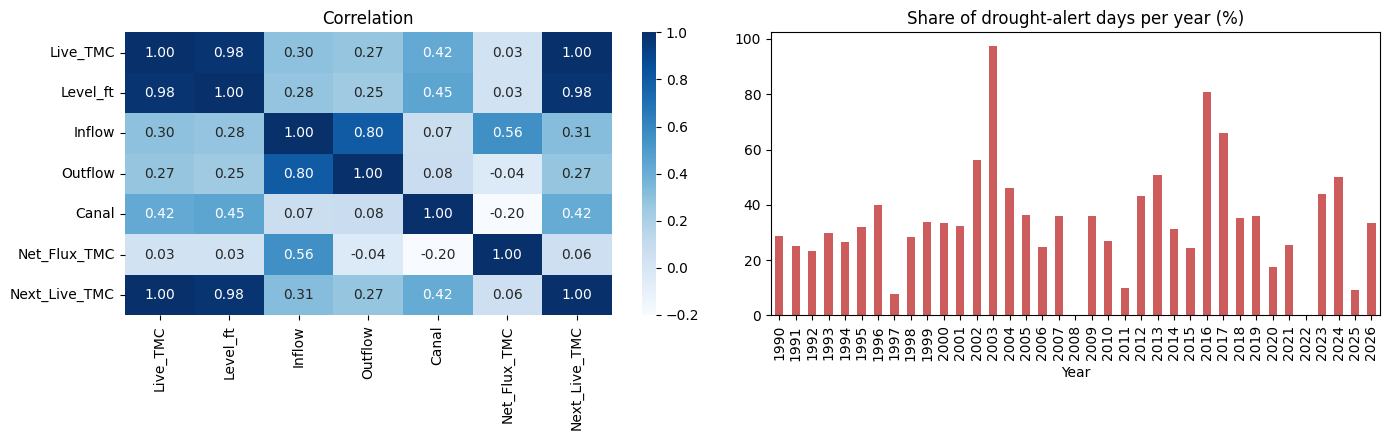

In [16]:
fig,ax=plt.subplots(1,2,figsize=(14,4.5))
sns.heatmap(df[['Live_TMC','Level_ft','Inflow','Outflow','Canal','Net_Flux_TMC','Next_Live_TMC']].corr(),annot=True,fmt='.2f',cmap='Blues',ax=ax[0])
ax[0].set_title('Correlation')
(df.groupby(df['Date'].dt.year)['Drought_Alert'].mean()*100).plot(kind='bar',ax=ax[1],color='indianred')
ax[1].set_title('Share of drought-alert days per year (%)'); ax[1].set_xlabel('Year')
plt.tight_layout(); plt.show()

## 6. Train-test split
One split for both tasks (80% train, 20% test), as in the lectures.

In [17]:
x=df[['Live_TMC','Level_ft','Inflow','Outflow','Canal']]
y=df['Next_Live_TMC']
yc=df['Drought_Alert']
x_train,x_test,y_train,y_test,yc_train,yc_test=train_test_split(x,y,yc,test_size=0.2,random_state=42)
print('Train:',len(x_train),'Test:',len(x_test))

Train: 10750 Test: 2688


## 7. Regression: predict next-day storage
Persistence baseline (tomorrow = today), Simple Linear Regression (today's storage only), Multiple Linear Regression (5 inputs) and Polynomial Regression (degree 2 on storage and net flux).

In [18]:
def scores(y_true,y_pred):
    return {'MAE':mean_absolute_error(y_true,y_pred),'MSE':mean_squared_error(y_true,y_pred),
            'RMSE':np.sqrt(mean_squared_error(y_true,y_pred)),'R2':r2_score(y_true,y_pred)}

reg_results={}
reg_results['Persistence (tomorrow = today)']=scores(y_test,x_test['Live_TMC'])

slr=LinearRegression()
slr.fit(x_train[['Live_TMC']],y_train)
reg_results['Simple Linear (storage only)']=scores(y_test,slr.predict(x_test[['Live_TMC']]))

mlr=LinearRegression()
mlr.fit(x_train,y_train)
y_pred_mlr=mlr.predict(x_test)
reg_results['Multiple Linear']=scores(y_test,y_pred_mlr)

poly=PolynomialFeatures(degree=2,include_bias=False)
xp_train=poly.fit_transform(df.loc[x_train.index,['Live_TMC','Net_Flux_TMC']])
xp_test=poly.transform(df.loc[x_test.index,['Live_TMC','Net_Flux_TMC']])
pm=LinearRegression()
pm.fit(xp_train,y_train)
reg_results['Polynomial (degree 2)']=scores(y_test,pm.predict(xp_test))

reg_table=pd.DataFrame(reg_results).T
print(reg_table.round(4))
print('MLR coefficients:',{c:round(float(v),4) for c,v in zip(x.columns,mlr.coef_)})

                                   MAE     MSE    RMSE      R2
Persistence (tomorrow = today)  0.2615  0.2969  0.5449  0.9985
Simple Linear (storage only)    0.2620  0.2968  0.5448  0.9985
Multiple Linear                 0.1279  0.1231  0.3509  0.9994
Polynomial (degree 2)           0.1187  0.0915  0.3024  0.9996
MLR coefficients: {'Live_TMC': 0.9957, 'Level_ft': 0.0023, 'Inflow': 0.0001, 'Outflow': -0.0001, 'Canal': -0.0001}


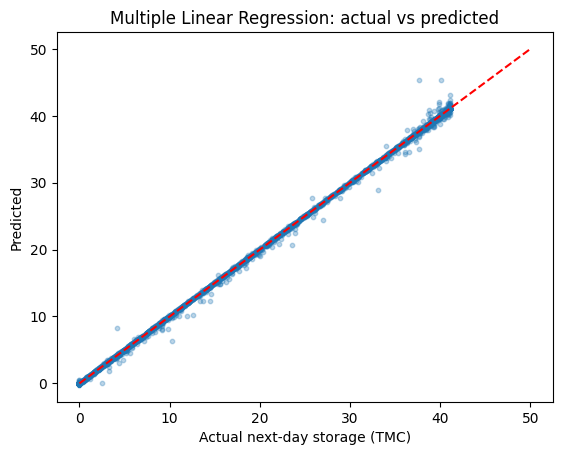

In [19]:
plt.scatter(y_test,y_pred_mlr,alpha=0.3,s=10)
plt.plot([0,50],[0,50],'r--')
plt.xlabel('Actual next-day storage (TMC)'); plt.ylabel('Predicted'); plt.title('Multiple Linear Regression: actual vs predicted')
plt.show()

## 8. Classification: predict the drought alert
Rule baseline (alert if today's storage is already below the threshold), Logistic Regression, KNN (k = 5) and Decision Tree (depth 6). Features are scaled first (fit on the training data only).

In [20]:
sc=StandardScaler()
xs_train=sc.fit_transform(x_train)
xs_test=sc.transform(x_test)

def clf_scores(y_true,pred,prob=None):
    out={'Accuracy':accuracy_score(y_true,pred),'Precision':precision_score(y_true,pred),'Recall':recall_score(y_true,pred),'F1':f1_score(y_true,pred)}
    if prob is not None:
        out['AUC']=roc_auc_score(y_true,prob); out['LogLoss']=log_loss(y_true,prob)
    return out

models={'Logistic Regression':LogisticRegression(max_iter=1000),
        'KNN (k=5)':KNeighborsClassifier(n_neighbors=5),
        'Decision Tree (depth 6)':DecisionTreeClassifier(max_depth=6,min_samples_leaf=10,random_state=42)}

rule=(x_test['Live_TMC']<12.363).astype(int)
clf_results={'Rule: today below threshold':clf_scores(yc_test,rule)}
preds={'Rule: today below threshold':rule}
for name,m in models.items():
    m.fit(xs_train,yc_train)
    preds[name]=m.predict(xs_test)
    clf_results[name]=clf_scores(yc_test,preds[name],m.predict_proba(xs_test)[:,1])

clf_table=pd.DataFrame(clf_results).T
print(clf_table.round(4))

                             Accuracy  Precision  Recall      F1     AUC  \
Rule: today below threshold    0.9940     0.9925  0.9904  0.9914     NaN   
Logistic Regression            0.9989     0.9989  0.9979  0.9984  1.0000   
KNN (k=5)                      0.9955     0.9957  0.9914  0.9936  0.9999   
Decision Tree (depth 6)        0.9985     0.9989  0.9968  0.9979  0.9997   

                             LogLoss  
Rule: today below threshold      NaN  
Logistic Regression           0.0172  
KNN (k=5)                     0.0111  
Decision Tree (depth 6)       0.0167  


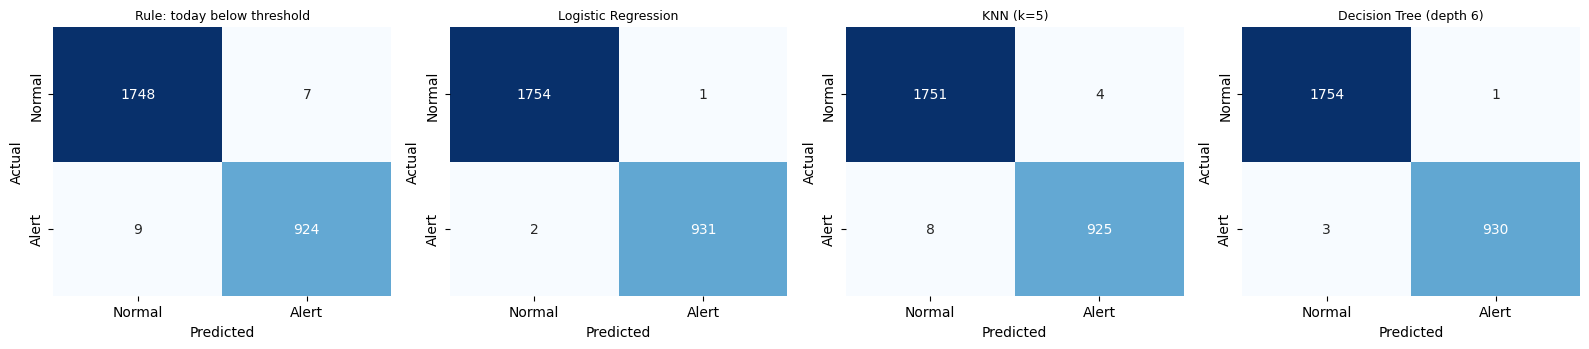

In [21]:
fig,ax=plt.subplots(1,4,figsize=(16,3.6))
for a,(name,p) in zip(ax,preds.items()):
    sns.heatmap(confusion_matrix(yc_test,p),annot=True,fmt='d',cmap='Blues',cbar=False,ax=a,xticklabels=['Normal','Alert'],yticklabels=['Normal','Alert'])
    a.set_title(name,fontsize=9); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 9. Check with a time-based split
Storage on neighbouring days is almost the same, so a random split can look too good. Here the models are trained on data **before 2018** and tested on 2018 onwards.

In [22]:
train=df[df['Date']<'2018-01-01']
test=df[df['Date']>='2018-01-01']
cols=['Live_TMC','Level_ft','Inflow','Outflow','Canal']

m1=LinearRegression().fit(train[cols],train['Next_Live_TMC'])
sc2=StandardScaler().fit(train[cols])
m2=LogisticRegression(max_iter=1000).fit(sc2.transform(train[cols]),train['Drought_Alert'])
rule2=(test['Live_TMC']<12.363).astype(int)

time_check=pd.DataFrame({
    'Persistence MAE':[mean_absolute_error(test['Next_Live_TMC'],test['Live_TMC'])],
    'MLR MAE':[mean_absolute_error(test['Next_Live_TMC'],m1.predict(test[cols]))],
    'Persistence RMSE':[np.sqrt(mean_squared_error(test['Next_Live_TMC'],test['Live_TMC']))],
    'MLR RMSE':[np.sqrt(mean_squared_error(test['Next_Live_TMC'],m1.predict(test[cols])))],
    'Rule F1':[f1_score(test['Drought_Alert'],rule2)],
    'Logistic F1':[f1_score(test['Drought_Alert'],m2.predict(sc2.transform(test[cols])))]})
print('Train rows:',len(train),'| Test rows:',len(test))
print(time_check.round(4).T)

Train rows: 10217 | Test rows: 3221
                       0
Persistence MAE   0.2497
MLR MAE           0.1401
Persistence RMSE  0.5465
MLR RMSE          0.4838
Rule F1           0.9899
Logistic F1       0.9972


## 10. Try it on example days

In [23]:
# example inputs: storage, level, inflow, outflow, canal
examples={'Dry summer day':[9.85,2437.6,380,1850,620],
          'Monsoon flood day':[41.0,2468.8,68500,65000,3800],
          'Normal post-monsoon day':[32.5,2462.3,4200,3500,1500]}
for name,vals in examples.items():
    day=pd.DataFrame([vals],columns=x.columns)
    nxt=mlr.predict(day)[0]
    prob=models['Logistic Regression'].predict_proba(sc.transform(day))[0,1]
    print(name,'-> predicted next-day storage: %.2f TMC | drought-alert probability: %.2f'%(nxt,prob))

Dry summer day -> predicted next-day storage: 9.72 TMC | drought-alert probability: 0.99
Monsoon flood day -> predicted next-day storage: 41.05 TMC | drought-alert probability: 0.00
Normal post-monsoon day -> predicted next-day storage: 32.42 TMC | drought-alert probability: 0.00


## 11. Findings and limitations
**Regression (random split).** All models have R² ≈ 0.999, but so does the persistence baseline (0.999), because storage changes slowly from day to day. The useful comparison is the error: Multiple Linear Regression has MAE 0.128 TMC vs 0.261 for persistence (51% lower), RMSE 0.351 vs 0.545 (36% lower) and MSE 59% lower. Polynomial Regression is a bit better still (RMSE 0.302, MAE 0.119), so a small curved effect exists, but the gain over the linear model is modest. Simple Linear Regression on storage alone (RMSE 0.545) is no better than persistence because its slope is almost 1. This matches the water-balance idea: tomorrow's storage ≈ today's storage + net flux. RMSE and MSE are driven by a few monsoon-flood days with big changes, so they move a lot with the data split; MAE is the steadier measure.

**Classification (random split).** Drought-alert days are 34.0% of 13,438 days. The simple rule "alert if today is already below the threshold" scores accuracy 0.9940 and F1 0.9914. The models are only slightly better (best F1: Logistic Regression, 0.9984). **Tomorrow's alert is almost the same as today's status**, so these scores are high mainly because the task is easy. The models' value is catching days where a large inflow or outflow tips storage across the threshold.

**Time-based check (train before 2018, test from 2018, 3,221 test days).** MLR MAE 0.140 vs persistence 0.250 (44% lower); alert F1: rule 0.990, Logistic Regression 0.997. MLR RMSE is 0.484 here vs 0.351 on the random split, so the random-split errors are the optimistic ones: neighbouring days in train and test are almost identical. Quote both in the report.

**Data quality note.** A few records in the raw file were impossible (storage above the design capacity, one-day jumps of 10 to 33 TMC that the flows cannot explain, two level typing errors) and were removed (Section 4). Left in, a handful of such days would dominate the squared errors (MSE, RMSE).

**Limitations.** (1) Only next-day prediction; no rainfall or catchment data. (2) Gate and canal operations are human decisions. (3) The 12.363 TMC drought threshold is an assumption (25% of design capacity applied to live storage), not an official rule. (4) One dam, records from 1990-01-01 to 2026-10-28. (5) This is a student model, not an operational warning system.